# Laboratorio # 4 — Análisis Exploratorio de Datos (EDA)

**Universidad Técnica Nacional**
**Curso:** Minería de Datos — ISW-911
**Asignación:** Laboratorio # 4 (grupal, investigación)
**Archivo:** `lab4_IC2025.ipynb`

**Integrantes del grupo:**

| # | Nombre completo | Carné |
|---|---|---|
| 1 | _[Nombre del integrante 1]_ | _[carné]_ |
| 2 | _[Nombre del integrante 2]_ | _[carné]_ |
| 3 | _[Nombre del integrante 3]_ | _[carné]_ |

---

### Descripción del conjunto de datos

El conjunto de datos proviene del **data warehouse `InvacomDW`** del proyecto del curso (autorizado por el profesor). Se construyó con la consulta [`sql/dataset_hogares.sql`](sql/dataset_hogares.sql), que genera **un registro por hogar** (2 500 hogares) uniendo:

* **`DimHogar`**: características demográficas del hogar (edad, ingreso, estado civil, vivienda, composición, tamaño e hijos).
* **`FactVenta`** + `DimPeriodo` + `DimProducto`: métricas de compra agregadas por hogar durante ~2 años (711 días).
* **`coupon_redempt`**: cantidad de cupones de campaña canjeados por el hogar.

El archivo resultante se publicó en GitHub y **se lee directamente desde el repositorio** (punto 3):
<https://github.com/Eyner1/Laboratorio-4---Miner-a-de-Datos-ISW-911---EDA-dataset-InvacomDW>

## 1. Librerías

Todo el ejercicio se realiza en **Python** (punto 1) con `pandas` y `numpy` para manipular datos, `matplotlib`, `seaborn` y `missingno` para la evidencia gráfica y `scikit-learn` para la estandarización y la validación del modelo candidato.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, KFold

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Lectura del conjunto de datos desde GitHub (puntos 2 y 3)

Se usa el enlace **Raw** del archivo para que `pd.read_csv()` reciba el CSV y no la página HTML de GitHub. Se indica `encoding="utf-8-sig"` porque el archivo trae un BOM al inicio; sin él la primera columna quedaría con un carácter extraño en el nombre.

In [2]:
URL_DATASET = (
    "https://raw.githubusercontent.com/Eyner1/"
    "Laboratorio-4---Miner-a-de-Datos-ISW-911---EDA-dataset-InvacomDW/"
    "main/data/hogares_invacom.csv"
)

df_original = pd.read_csv(URL_DATASET, encoding="utf-8-sig")
df = df_original.copy()   # se trabaja sobre una copia para conservar el original
print(f"Dataset cargado desde GitHub: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset cargado desde GitHub: 2,500 filas x 21 columnas


## 3. Características principales del conjunto de datos (punto 4)

Se aplican las funciones **básicas** de `pandas` para conocer la estructura del dataset: dimensiones, primeras y últimas filas, una muestra aleatoria, tipos de datos, estadísticas descriptivas, cardinalidad, frecuencias, duplicados y distribuciones.

### 3.1 Dimensiones — `shape`

In [3]:
filas, columnas = df.shape
print(f"Filas (hogares): {filas:,}")
print(f"Columnas (variables): {columnas}")

Filas (hogares): 2,500
Columnas (variables): 21


### 3.2 Primeras filas — `head()`

In [4]:
df.head()

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
0,1,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,"4,330.16",86,50.35,1997,677,2,68,51,706,-697.04,-80.56,5.00,GROCERY
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,954.34",45,43.43,834,546,5,35,103,668,-334.99,-9.00,NaN,GROCERY
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,653.21",47,56.45,8540,516,3,37,113,703,-675.16,-61.19,NaN,GROCERY
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,200.11",30,40.00,382,164,6,26,104,627,-115.65,-2.50,NaN,GROCERY
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,779.06,40,19.48,245,199,3,27,85,703,-118.33,0.00,NaN,GROCERY


### 3.3 Últimas filas — `tail()`

In [5]:
df.tail()

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
2495,2496,45-54,A,75-99K,Homeowner,Unknown,3,1,"4,339.66",63,68.88,130304,758,3,48,117,683,"-1,115.09",-51.60,11.00,GROCERY
2496,2497,45-54,U,35-49K,Unknown,Single Male,1,None/Unknown,"7,111.98",221,32.18,61236,991,12,86,78,700,"-1,341.03",-16.84,NaN,GROCERY
2497,2498,25-34,U,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,"2,601.60",172,15.13,31339,642,7,67,105,710,-279.40,0.00,NaN,GROCERY
2498,2499,25-34,U,Under 15K,Unknown,2 Adults Kids,3,1,"3,394.07",90,37.71,143449,709,9,54,70,709,-498.10,-3.55,NaN,GROCERY
2499,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"5,486.16",113,48.55,247365,1082,9,64,79,708,-958.41,-96.61,3.00,GROCERY


### 3.4 Muestra aleatoria — `sample()`

In [6]:
df.sample(5, random_state=42)

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
1447,1448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,927.33",80,24.09,4367,141,2,35,101,651,-160.62,0.00,NaN,GROCERY
1114,1115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,828.64",51,35.86,127133,282,4,25,49,708,-149.88,-1.85,NaN,GROCERY
1064,1065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"5,167.16",50,103.34,2360,1037,2,42,36,705,"-1,107.35",-6.85,NaN,GROCERY
2287,2288,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,093.06",157,13.33,12915,483,7,57,79,711,-416.21,-7.80,NaN,GROCERY
1537,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,504.92,32,15.78,274,227,3,23,63,707,-96.65,-1.25,NaN,GROCERY


### 3.5 Estructura, tipos y no nulos — `info()`

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   household_key        2500 non-null   int64  
 1   age_desc             801 non-null    str    
 2   marital_status_code  801 non-null    str    
 3   income_desc          801 non-null    str    
 4   homeowner_desc       801 non-null    str    
 5   hh_comp_desc         801 non-null    str    
 6   household_size_desc  801 non-null    str    
 7   kid_category_desc    801 non-null    str    
 8   total_sales          2500 non-null   float64
 9   num_baskets          2500 non-null   int64  
 10  avg_basket_value     2500 non-null   float64
 11  total_quantity       2500 non-null   int64  
 12  distinct_products    2500 non-null   int64  
 13  distinct_stores      2500 non-null   int64  
 14  active_weeks         2500 non-null   int64  
 15  first_day            2500 non-null   int64  
 16 

### 3.6 Tipos de datos — `dtypes`

In [8]:
df.dtypes.to_frame('tipo')

,tipo
household_key,int64
age_desc,str
marital_status_code,str
income_desc,str
homeowner_desc,str
hh_comp_desc,str
household_size_desc,str
kid_category_desc,str
total_sales,float64
num_baskets,int64


### 3.7 Estadísticas descriptivas de variables numéricas — `describe()`

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
household_key,"2,500.00","1,250.50",721.83,1.00,625.75,"1,250.50","1,875.25","2,500.00"
total_sales,"2,500.00","3,222.99","3,349.03",8.17,970.74,"2,157.75","4,413.32","38,319.79"
num_baskets,"2,500.00",110.59,115.67,1.00,39.00,79.00,142.25,"1,300.00"
avg_basket_value,"2,500.00",31.62,19.05,2.39,18.33,27.42,40.55,165.83
total_quantity,"2,500.00","104,274.25","244,456.08",5.00,770.00,"11,084.50","87,640.00","4,479,917.00"
distinct_products,"2,500.00",560.59,435.96,4.00,230.75,455.00,788.00,"3,159.00"
distinct_stores,"2,500.00",5.46,3.52,1.00,3.00,5.00,7.00,30.00
active_weeks,"2,500.00",49.59,25.54,1.00,28.00,50.00,71.00,102.00
first_day,"2,500.00",65.94,39.15,1.00,36.00,69.00,95.00,671.00
last_day,"2,500.00",685.43,62.79,54.00,691.00,705.00,710.00,711.00


### 3.8 Estadísticas descriptivas de variables categóricas — `describe()`

In [10]:
cols_texto = df.select_dtypes(exclude="number").columns
df[cols_texto].describe().T

,count,unique,top,freq
age_desc,801,6,45-54,288
marital_status_code,801,3,U,344
income_desc,801,12,50-74K,192
homeowner_desc,801,5,Homeowner,504
hh_comp_desc,801,6,2 Adults No Kids,255
household_size_desc,801,5,2,318
kid_category_desc,801,4,None/Unknown,558
top_department,2500,13,GROCERY,2380


### 3.9 Cardinalidad (valores únicos) — `nunique()`

In [11]:
df.nunique().sort_values().to_frame('valores_unicos')

,valores_unicos
marital_status_code,3
kid_category_desc,4
homeowner_desc,5
household_size_desc,5
age_desc,6
hh_comp_desc,6
income_desc,12
top_department,13
distinct_stores,25
coupons_redeemed,29


### 3.10 Frecuencias de las variables categóricas — `value_counts()`

In [12]:
for col in cols_texto:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

--- age_desc ---
age_desc
NaN      1699
45-54     288
35-44     194
25-34     142
65+        72
55-64      59
19-24      46 

--- marital_status_code ---
marital_status_code
NaN    1699
U       344
A       340
B       117 

--- income_desc ---
income_desc
NaN          1699
50-74K        192
35-49K        172
75-99K         96
25-34K         77
15-24K         74
Under 15K      61
125-149K       38
100-124K       34
150-174K       30
250K+          11
175-199K       11
200-249K        5 

--- homeowner_desc ---
homeowner_desc
NaN                1699
Homeowner           504
Unknown             233
Renter               42
Probable Renter      11
Probable Owner       11 

--- hh_comp_desc ---
hh_comp_desc
NaN                 1699
2 Adults No Kids     255
2 Adults Kids        187
Single Female        144
Single Male           95
Unknown               73
1 Adult Kids          47 

--- household_size_desc ---
household_size_desc
NaN    1699
2       318
1       255
3       109
5+       66
4    

### 3.11 Registros duplicados — `duplicated()`

In [13]:
print("Filas duplicadas:", df.duplicated().sum())
print("household_key duplicados:", df["household_key"].duplicated().sum())

Filas duplicadas: 0
household_key duplicados: 0


### 3.12 Distribución de las variables numéricas — `hist()`

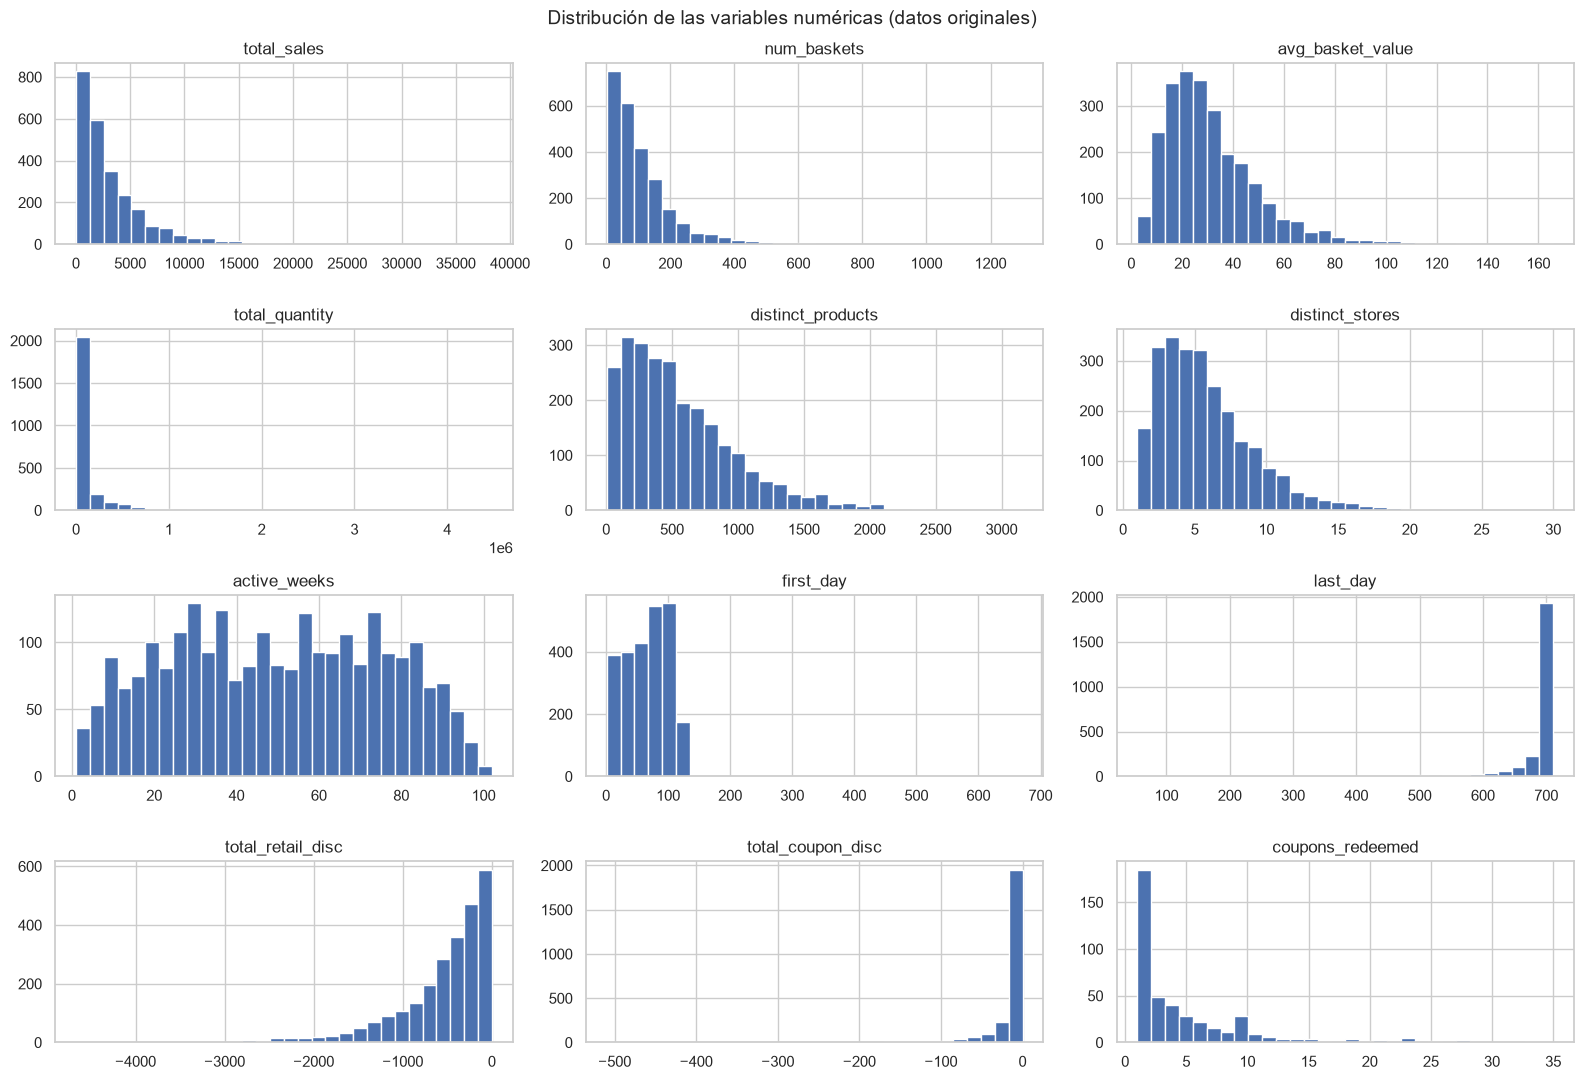

In [14]:
df.drop(columns="household_key").hist(bins=30, figsize=(16, 11), edgecolor="white")
plt.suptitle("Distribución de las variables numéricas (datos originales)", fontsize=14)
plt.tight_layout()
plt.show()

**Hallazgos iniciales**

* El dataset tiene **2 500 hogares** y **21 variables**: 1 identificador, 7 demográficas (texto), 12 métricas de compra (numéricas) y 1 categórica de comportamiento (`top_department`).
* No hay filas ni identificadores duplicados: cada fila es un hogar único.
* Las variables demográficas y `coupons_redeemed` tienen menos valores no nulos que el resto, así que **hay valores faltantes** (se analizan en la sección 5).
* Casi todas las métricas de compra tienen **asimetría positiva fuerte** (cola larga a la derecha). Por ejemplo, `total_quantity` tiene una media de ~104 mil y una mediana de ~11 mil, lo que anticipa **valores atípicos** (sección 6).
* Los descuentos (`total_retail_disc`, `total_coupon_disc`) son **negativos** porque en el origen se registran como resta al precio.
* `top_department` está muy desbalanceada: ~95 % de los hogares gastan más en `GROCERY`.

## 4. Cambio de nombres de las columnas a español (punto 5)

Se renombran todas las columnas con un diccionario explícito y en formato `snake_case`, sin tildes ni espacios, para facilitar su uso en código. Además se traducen los códigos de `estado_civil`, que vienen cifrados (`A` = casado, `B` = soltero, `U` = desconocido), para que el análisis se lea con claridad.

In [15]:
nombres_es = {
    "household_key":       "id_hogar",
    "age_desc":            "rango_edad",
    "marital_status_code": "estado_civil",
    "income_desc":         "rango_ingreso",
    "homeowner_desc":      "tipo_vivienda",
    "hh_comp_desc":        "composicion_hogar",
    "household_size_desc": "tamano_hogar",
    "kid_category_desc":   "cantidad_hijos",
    "total_sales":         "total_ventas",
    "num_baskets":         "cantidad_compras",
    "avg_basket_value":    "ticket_promedio",
    "total_quantity":      "cantidad_articulos",
    "distinct_products":   "productos_distintos",
    "distinct_stores":     "tiendas_distintas",
    "active_weeks":        "semanas_activas",
    "first_day":           "primer_dia_compra",
    "last_day":            "ultimo_dia_compra",
    "total_retail_disc":   "descuento_tienda",
    "total_coupon_disc":   "descuento_cupon",
    "coupons_redeemed":    "cupones_canjeados",
    "top_department":      "departamento_principal",
}
df = df.rename(columns=nombres_es)

df["estado_civil"] = df["estado_civil"].map({"A": "Casado", "B": "Soltero", "U": "Desconocido"})

pd.DataFrame({"original": list(nombres_es.keys()), "español": list(nombres_es.values())})

,original,español
0,household_key,id_hogar
1,age_desc,rango_edad
2,marital_status_code,estado_civil
3,income_desc,rango_ingreso
4,homeowner_desc,tipo_vivienda
5,hh_comp_desc,composicion_hogar
6,household_size_desc,tamano_hogar
7,kid_category_desc,cantidad_hijos
8,total_sales,total_ventas
9,num_baskets,cantidad_compras


In [16]:
df.head(3)

,id_hogar,rango_edad,estado_civil,rango_ingreso,tipo_vivienda,composicion_hogar,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,cantidad_articulos,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,departamento_principal
0,1,65+,Casado,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,"4,330.16",86,50.35,1997,677,2,68,51,706,-697.04,-80.56,5.00,GROCERY
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,954.34",45,43.43,834,546,5,35,103,668,-334.99,-9.00,NaN,GROCERY
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,653.21",47,56.45,8540,516,3,37,113,703,-675.16,-61.19,NaN,GROCERY


In [17]:
# Grupos de columnas que se reutilizan en el resto del notebook
COLS_DEMOGRAFICAS = ["rango_edad", "estado_civil", "rango_ingreso", "tipo_vivienda",
                     "composicion_hogar", "tamano_hogar", "cantidad_hijos"]
COLS_NUMERICAS = ["total_ventas", "cantidad_compras", "ticket_promedio", "cantidad_articulos",
                  "productos_distintos", "tiendas_distintas", "semanas_activas",
                  "primer_dia_compra", "ultimo_dia_compra", "descuento_tienda",
                  "descuento_cupon", "cupones_canjeados"]

## 5. Determinación de valores nulos (punto 6)

### 5.1 Conteo y porcentaje de nulos por columna

In [18]:
resumen_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("nulos", ascending=False)

print(f"Total de celdas nulas: {df.isna().sum().sum():,} de {df.size:,} "
      f"({df.isna().sum().sum() / df.size:.1%})")
resumen_nulos[resumen_nulos["nulos"] > 0]

Total de celdas nulas: 13,959 de 52,500 (26.6%)


,nulos,porcentaje
cupones_canjeados,2066,82.64
rango_ingreso,1699,67.96
estado_civil,1699,67.96
tipo_vivienda,1699,67.96
rango_edad,1699,67.96
cantidad_hijos,1699,67.96
composicion_hogar,1699,67.96
tamano_hogar,1699,67.96


### 5.2 Evidencia gráfica: porcentaje de nulos por variable

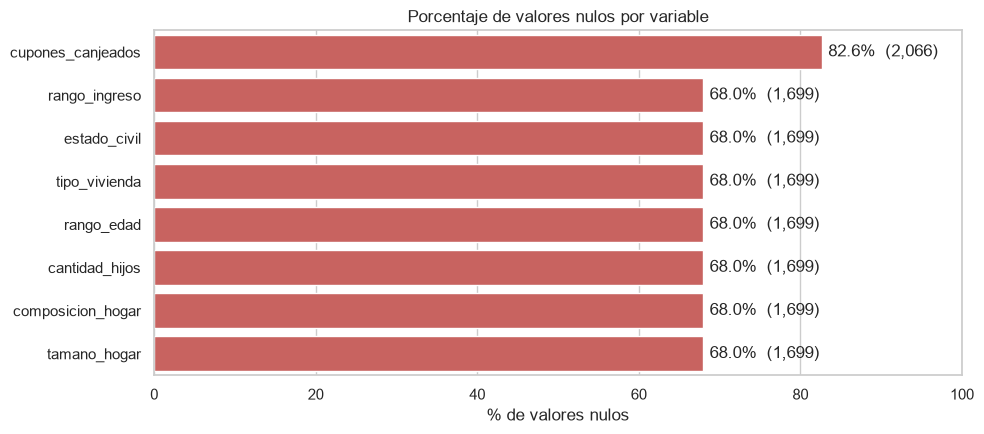

In [19]:
con_nulos = resumen_nulos[resumen_nulos["nulos"] > 0]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=con_nulos["porcentaje"], y=con_nulos.index, color="#d9534f", ax=ax)
for i, (n, p) in enumerate(zip(con_nulos["nulos"], con_nulos["porcentaje"])):
    ax.text(p + 0.8, i, f"{p:.1f}%  ({n:,})", va="center")
ax.set_xlim(0, 100)
ax.set_xlabel("% de valores nulos")
ax.set_ylabel("")
ax.set_title("Porcentaje de valores nulos por variable")
plt.tight_layout()
plt.show()

### 5.3 Evidencia gráfica: matriz de nulidad (`missingno.matrix`)

Cada línea blanca es un valor faltante. Permite ver **en qué filas** faltan los datos.

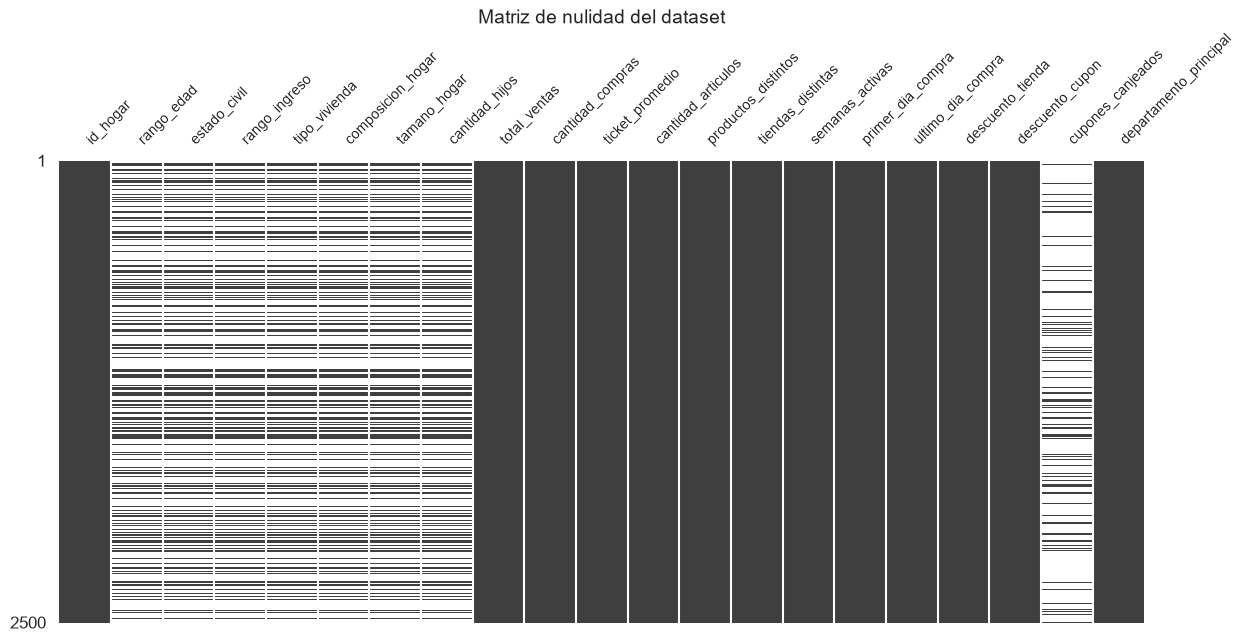

In [20]:
msno.matrix(df, figsize=(14, 6), fontsize=10, sparkline=False)
plt.title("Matriz de nulidad del dataset", fontsize=14)
plt.show()

### 5.4 Evidencia gráfica: correlación de nulidad (`missingno.heatmap`)

Mide si los nulos de una variable aparecen junto con los de otra (1 = siempre faltan juntos).

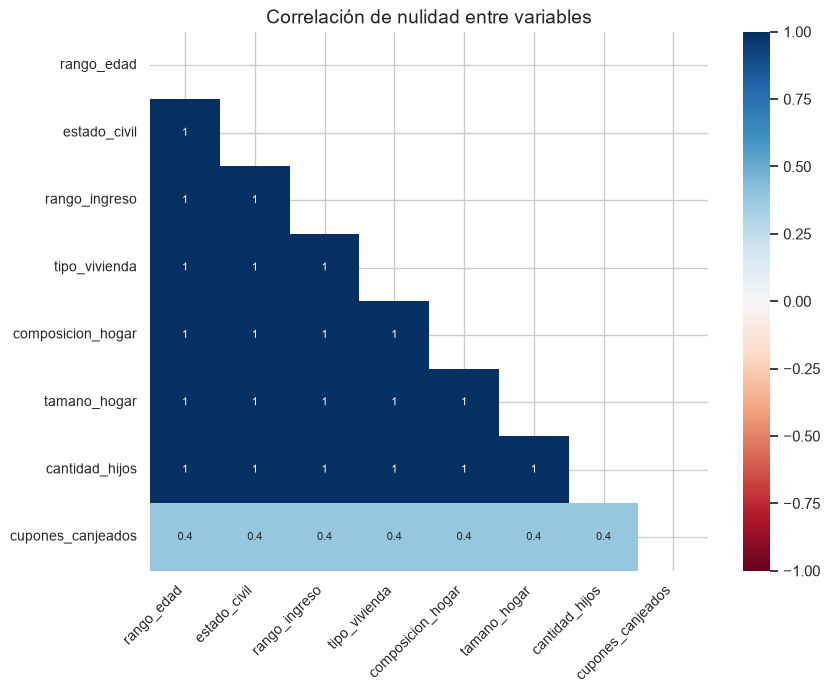

In [21]:
msno.heatmap(df, figsize=(9, 7), fontsize=10)
plt.title("Correlación de nulidad entre variables", fontsize=14)
plt.show()

In [22]:
# Verificación numérica: ¿las 7 columnas demográficas faltan siempre en las mismas filas?
falta_alguna = df[COLS_DEMOGRAFICAS].isna().any(axis=1)
faltan_todas = df[COLS_DEMOGRAFICAS].isna().all(axis=1)
print("Hogares sin ningún dato demográfico:", faltan_todas.sum())
print("¿Los nulos demográficos coinciden siempre en bloque?:", (falta_alguna == faltan_todas).all())

# ¿Los nulos de cupones_canjeados son hogares que sí compraron?
nulos_cupon = df["cupones_canjeados"].isna()
print("\nHogares con cupones_canjeados nulo:", nulos_cupon.sum())
print("De ellos, con compras registradas (cantidad_compras > 0):",
      (df.loc[nulos_cupon, "cantidad_compras"] > 0).sum())

Hogares sin ningún dato demográfico: 1699
¿Los nulos demográficos coinciden siempre en bloque?: True

Hogares con cupones_canjeados nulo: 2066
De ellos, con compras registradas (cantidad_compras > 0): 2066


**Hallazgos sobre valores nulos**

1. **Variables demográficas (7 columnas): 1 699 nulos cada una (67.96 %).** La matriz y el heatmap de nulidad (correlación = 1) muestran que faltan **en bloque**: un hogar tiene las 7 variables o no tiene ninguna. No son errores aislados de captura; ocurre que **solo 801 hogares respondieron la encuesta demográfica**. En el data warehouse el ETL había rellenado estos casos con el texto *"No informado"*, que en la extracción se convirtió otra vez en `NULL` para tratarlo como lo que es: un dato faltante.
2. **`cupones_canjeados`: 2 066 nulos (82.64 %).** Este nulo no es un dato desconocido. Proviene del `LEFT JOIN` con la tabla de canjes: el hogar **no aparece en `coupon_redempt` porque no canjeó ningún cupón**. Es un **nulo estructural que significa 0**.
3. Las métricas de compra **no tienen nulos**: todos los hogares registran al menos una compra.

Estas dos situaciones requieren tratamientos distintos (sección 7).

## 6. Determinación de valores atípicos (punto 7)

Se usa el **método del rango intercuartílico (IQR)**: un valor es atípico si está fuera de $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$. Además se calcula la **asimetría** (*skewness*) de cada variable.

In [23]:
def detectar_atipicos_iqr(datos, columnas, factor=1.5):
    '''Devuelve, por columna, los límites IQR y la cantidad/porcentaje de valores atípicos.'''
    filas = []
    for col in columnas:
        serie = datos[col].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - factor * iqr, q3 + factor * iqr
        n_atip = ((serie < lim_inf) | (serie > lim_sup)).sum()
        filas.append({"variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                      "lim_inferior": lim_inf, "lim_superior": lim_sup,
                      "minimo": serie.min(), "maximo": serie.max(),
                      "atipicos": n_atip, "%_atipicos": 100 * n_atip / len(serie),
                      "asimetria": serie.skew()})
    return pd.DataFrame(filas).set_index("variable")

tabla_atipicos = detectar_atipicos_iqr(df, COLS_NUMERICAS)
tabla_atipicos.sort_values("%_atipicos", ascending=False)

,Q1,Q3,IQR,lim_inferior,lim_superior,minimo,maximo,atipicos,%_atipicos,asimetria
variable,,,,,,,,,,
cantidad_articulos,770.00,"87,640.00","86,870.00","-129,535.00","217,945.00",5.00,"4,479,917.00",359,14.36,5.80
ultimo_dia_compra,691.00,710.00,19.00,662.50,738.50,54.00,711.00,326,13.04,-5.57
descuento_cupon,-14.21,0.00,14.21,-35.51,21.31,-509.83,0.00,304,12.16,-5.56
cupones_canjeados,1.00,7.00,6.00,-8.00,16.00,1.00,35.00,27,6.22,2.32
cantidad_compras,39.00,142.25,103.25,-115.88,297.12,1.00,"1,300.00",148,5.92,3.37
descuento_tienda,-756.62,-165.08,591.54,"-1,643.93",722.23,"-4,668.59",-0.25,129,5.16,-2.12
total_ventas,970.74,"4,413.32","3,442.58","-4,193.13","9,577.19",8.17,"38,319.79",127,5.08,2.41
ticket_promedio,18.33,40.55,22.22,-15.00,73.88,2.39,165.83,90,3.60,1.72
tiendas_distintas,3.00,7.00,4.00,-3.00,13.00,1.00,30.00,80,3.20,1.46


### 6.1 Evidencia gráfica: diagramas de caja (boxplots)

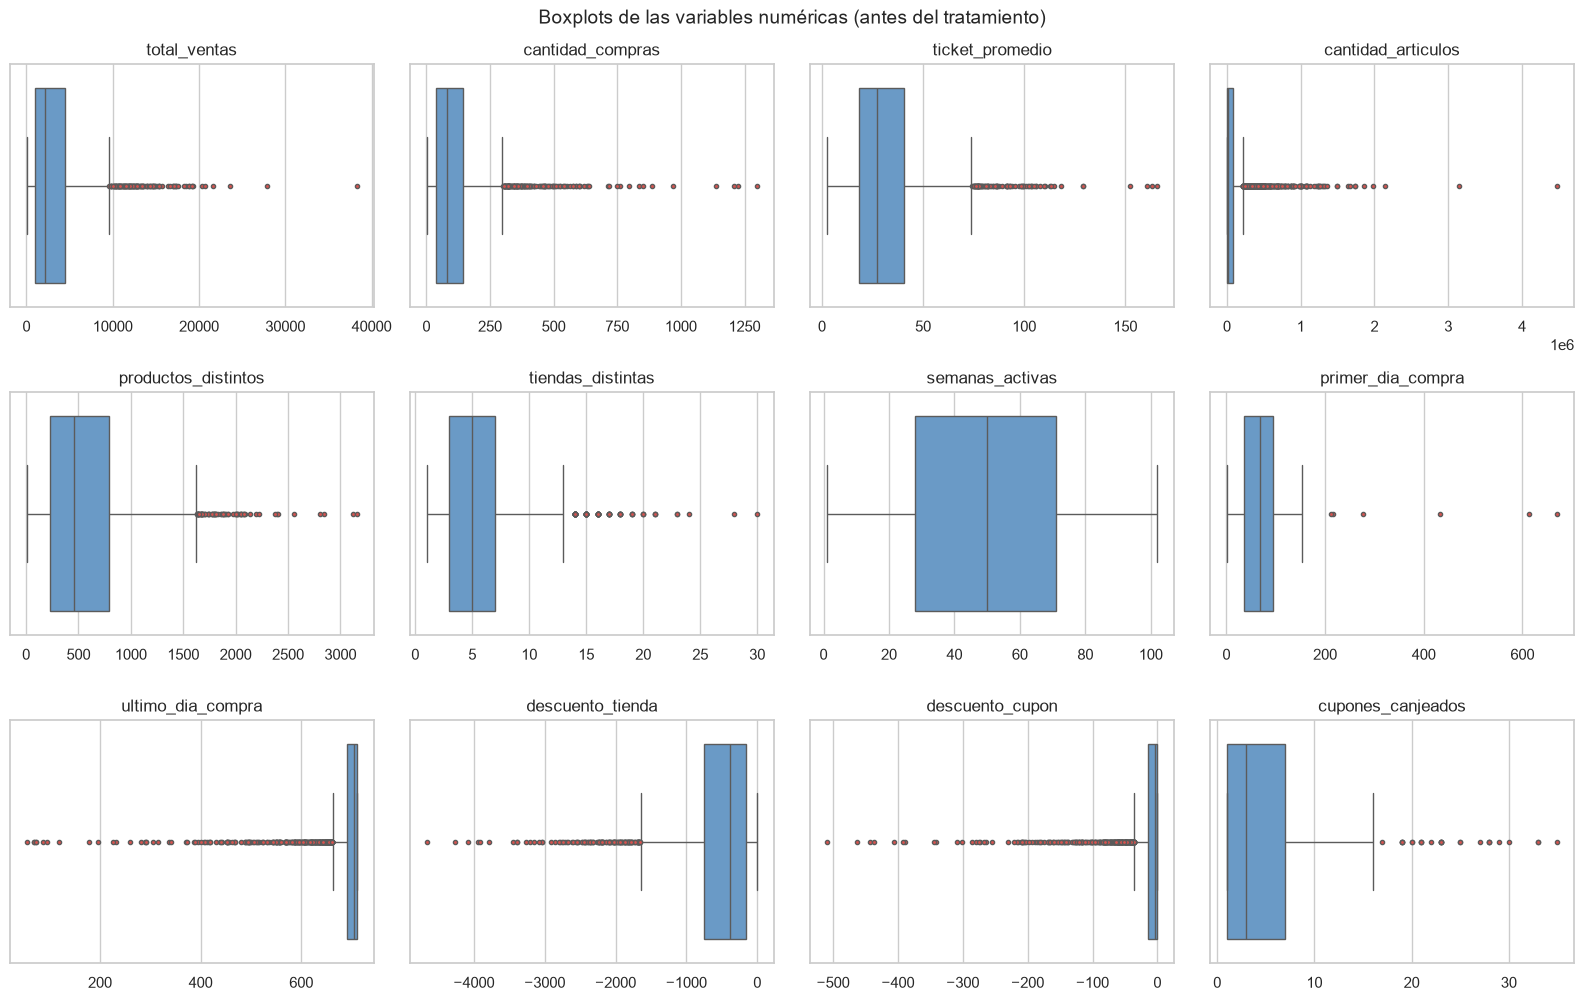

In [24]:
def graficar_boxplots(datos, columnas, titulo, color="#5b9bd5"):
    n = len(columnas)
    ncols = 4
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows))
    for ax, col in zip(axes.flat, columnas):
        sns.boxplot(x=datos[col], ax=ax, color=color,
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#d9534f"})
        ax.set_title(col)
        ax.set_xlabel("")
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

graficar_boxplots(df, COLS_NUMERICAS, "Boxplots de las variables numéricas (antes del tratamiento)")

### 6.2 Evidencia gráfica: cantidad de atípicos por variable

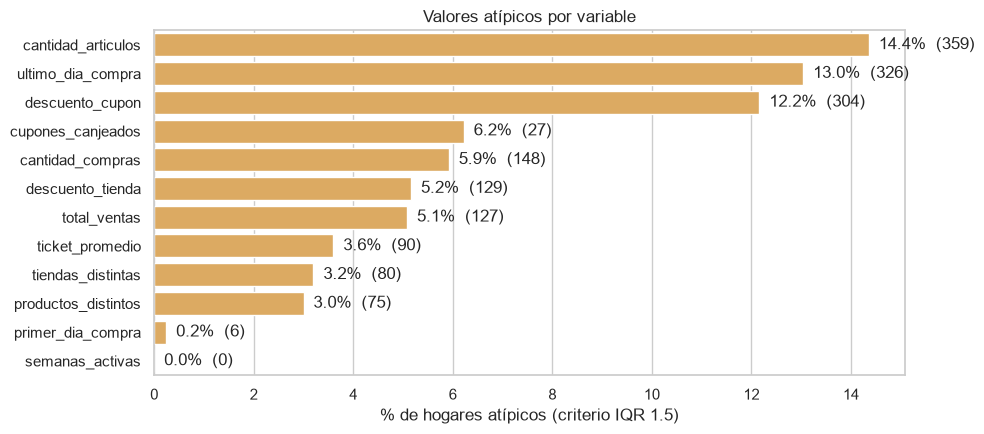

In [25]:
orden = tabla_atipicos.sort_values("%_atipicos", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=orden["%_atipicos"], y=orden.index, color="#f0ad4e", ax=ax)
for i, (n, p) in enumerate(zip(orden["atipicos"], orden["%_atipicos"])):
    ax.text(p + 0.2, i, f"{p:.1f}%  ({n})", va="center")
ax.set_xlabel("% de hogares atípicos (criterio IQR 1.5)")
ax.set_ylabel("")
ax.set_title("Valores atípicos por variable")
plt.tight_layout()
plt.show()

### 6.3 Caso extremo: `cantidad_articulos`

El máximo (~4.5 millones de unidades) no es plausible para compras de supermercado. Se revisa la relación con el departamento principal del hogar.

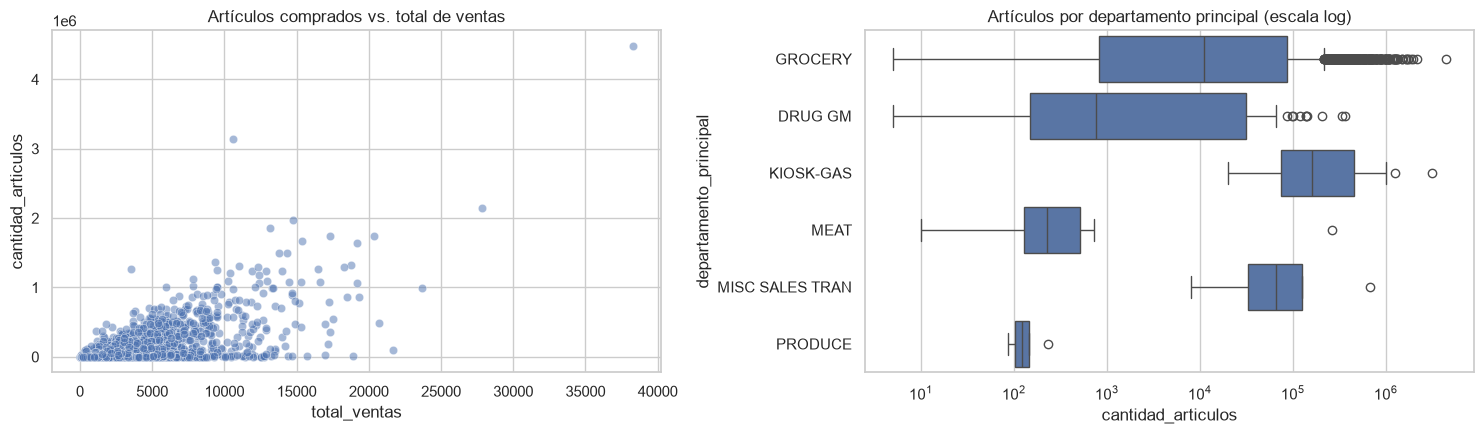

                      count       mean        std  min       50%        90%        95%          99%          max
cantidad_articulos 2,500.00 104,274.25 244,456.08 5.00 11,084.50 329,406.00 529,429.70 1,090,772.69 4,479,917.00


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.scatterplot(data=df, x="total_ventas", y="cantidad_articulos", alpha=0.5, ax=axes[0])
axes[0].set_title("Artículos comprados vs. total de ventas")
sns.boxplot(data=df, x="cantidad_articulos", y="departamento_principal", ax=axes[1],
            order=df["departamento_principal"].value_counts().index[:6])
axes[1].set_xscale("log")
axes[1].set_title("Artículos por departamento principal (escala log)")
plt.tight_layout()
plt.show()

print(df[["cantidad_articulos"]].describe(percentiles=[.5, .9, .95, .99]).T)

**Hallazgos sobre valores atípicos**

* Casi todas las métricas de compra tienen atípicos **solo en el extremo superior** (o inferior en los descuentos, que son negativos) y una **asimetría positiva marcada**. Es la distribución típica del consumo: pocos hogares compran muchísimo más que la mayoría.
* **`cantidad_articulos`** es el caso más grave (14 % de atípicos, asimetría ≈ 5.8). Al revisar en el data warehouse, las cantidades enormes vienen de los departamentos **`KIOSK-GAS`** (combustible) y **`MISC SALES TRAN`**, que registran la cantidad en **otra unidad de medida** (hasta 89 638 "unidades" en una sola línea). Es un **atípico de medición**, no de comportamiento.
* **`descuento_cupon`** presenta muchos "atípicos" porque más del 25 % de los hogares tiene descuento 0 y el IQR resulta muy estrecho.
* **`ultimo_dia_compra`** y **`primer_dia_compra`** tienen atípicos que representan hogares que **dejaron de comprar antes** o **empezaron más tarde**. Es información real del negocio (abandono de clientes) y no un error.
* **`semanas_activas`** no tiene atípicos.

Como cada fila es un hogar real y válido, **eliminar filas no es apropiado**: se perdería entre el 5 % y el 14 % de los clientes, justamente los de mayor valor. El tratamiento elegido se justifica en la sección siguiente.

## 7. Funciones de imputación y tratamiento (punto 8)

Se crean **funciones reutilizables** para tratar lo encontrado en las secciones 5 (nulos) y 6 (atípicos). Las decisiones son las siguientes:

| Hallazgo | Acción | Justificación |
|---|---|---|
| 7 variables demográficas con 68 % nulos en bloque | 1) Crear el indicador `tiene_demografia` (1/0). 2) Imputar con la categoría constante **`"Desconocido"`**. 3) Unificar los valores ya existentes `"Unknown"` / `"U"` en esa misma categoría. | Imputar con la **moda** inventaría información para 1 699 hogares (más de 2/3 del dataset) y distorsionaría las distribuciones: por ejemplo, el 80 % pasaría a tener "45-54 años". Eliminar esas filas perdería el 68 % de los datos. La categoría explícita conserva todos los hogares, no inventa datos y deja que el modelo aprenda si "no tener demografía" se relaciona con el comportamiento de compra. El indicador conserva esa información después de la codificación numérica. |
| `cupones_canjeados` nulo | Imputar con **0** | Es un nulo estructural: el hogar no aparece en la tabla de canjes porque **no canjeó cupones**. Imputar con media o mediana sería un error conceptual. |
| Atípicos en métricas de consumo | **Winsorización** (acotar) en los percentiles **1 y 99** | No se eliminan filas porque son hogares reales. Acotar limita la influencia de los extremos (sobre todo los errores de unidad de `cantidad_articulos`) sobre la media, la estandarización y los modelos lineales, sin perder registros. Se usan los percentiles 1-99 en lugar de los límites IQR porque, en distribuciones tan asimétricas, el IQR marcaría como atípico hasta el 14 % de los clientes legítimos. |
| Atípicos en `primer_dia_compra`, `ultimo_dia_compra` | **No se tratan** | Representan comportamiento real (abandono o ingreso tardío) y no errores. |
| `total_ventas` (variable objetivo) | **No se trata** | Es la variable que se quiere predecir (sección 12). Acotarla eliminaría la señal de los hogares de alto valor. |

In [27]:
def crear_indicador_faltante(datos, columnas, nombre_indicador):
    '''Crea una columna 1/0 que indica si el registro TIENE datos en las columnas dadas.
    Se debe ejecutar ANTES de imputar, para no perder la información de qué era faltante.'''
    datos = datos.copy()
    datos[nombre_indicador] = datos[columnas].notna().all(axis=1).astype(int)
    return datos


def imputar(datos, columnas, estrategia="constante", valor=None):
    '''Imputa valores nulos en las columnas indicadas.
    estrategia: 'constante' (usa `valor`), 'media', 'mediana' o 'moda'.'''
    datos = datos.copy()
    for col in columnas:
        if estrategia == "constante":
            relleno = valor
        elif estrategia == "media":
            relleno = datos[col].mean()
        elif estrategia == "mediana":
            relleno = datos[col].median()
        elif estrategia == "moda":
            relleno = datos[col].mode().iloc[0]
        else:
            raise ValueError(f"Estrategia no soportada: {estrategia}")
        n = datos[col].isna().sum()
        datos[col] = datos[col].fillna(relleno)
        print(f"  {col:<22} -> {n:>5} nulos imputados con {estrategia} = {relleno!r}")
    return datos


def unificar_categoria(datos, columnas, equivalentes, destino="Desconocido"):
    '''Reemplaza etiquetas equivalentes (ej. 'Unknown') por una sola categoría.'''
    datos = datos.copy()
    for col in columnas:
        datos[col] = datos[col].replace(list(equivalentes), destino)
    return datos


def tratar_atipicos(datos, columnas, metodo="percentil", p_inf=0.01, p_sup=0.99, factor=1.5):
    '''Acota (winsoriza) los valores atípicos sin eliminar filas.
    metodo='percentil': acota a los percentiles p_inf y p_sup.
    metodo='iqr'      : acota a Q1 - factor*IQR y Q3 + factor*IQR.'''
    datos = datos.copy()
    for col in columnas:
        if metodo == "percentil":
            lim_inf, lim_sup = datos[col].quantile([p_inf, p_sup])
        elif metodo == "iqr":
            q1, q3 = datos[col].quantile([0.25, 0.75])
            lim_inf, lim_sup = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)
        else:
            raise ValueError(f"Método no soportado: {metodo}")
        n = ((datos[col] < lim_inf) | (datos[col] > lim_sup)).sum()
        datos[col] = datos[col].clip(lim_inf, lim_sup)
        print(f"  {col:<22} -> {n:>4} valores acotados a [{lim_inf:,.2f}, {lim_sup:,.2f}]")
    return datos

### 7.1 Aplicación del tratamiento de nulos

In [28]:
df = crear_indicador_faltante(df, COLS_DEMOGRAFICAS, "tiene_demografia")
print("Hogares con demografía:", df["tiene_demografia"].sum(), "| sin demografía:",
      (df["tiene_demografia"] == 0).sum(), "\n")

print("Imputación de variables demográficas:")
df = imputar(df, COLS_DEMOGRAFICAS, estrategia="constante", valor="Desconocido")
df = unificar_categoria(df, ["tipo_vivienda", "composicion_hogar"], equivalentes=["Unknown"])

print("\nImputación de cupones canjeados:")
df = imputar(df, ["cupones_canjeados"], estrategia="constante", valor=0)

print("\nNulos restantes en el dataset:", df.isna().sum().sum())

Hogares con demografía: 801 | sin demografía: 1699 

Imputación de variables demográficas:
  rango_edad             ->  1699 nulos imputados con constante = 'Desconocido'
  estado_civil           ->  1699 nulos imputados con constante = 'Desconocido'
  rango_ingreso          ->  1699 nulos imputados con constante = 'Desconocido'
  tipo_vivienda          ->  1699 nulos imputados con constante = 'Desconocido'
  composicion_hogar      ->  1699 nulos imputados con constante = 'Desconocido'
  tamano_hogar           ->  1699 nulos imputados con constante = 'Desconocido'
  cantidad_hijos         ->  1699 nulos imputados con constante = 'Desconocido'

Imputación de cupones canjeados:
  cupones_canjeados      ->  2066 nulos imputados con constante = 0

Nulos restantes en el dataset: 0


### 7.2 Aplicación del tratamiento de atípicos

In [29]:
COLS_ACOTAR = ["cantidad_compras", "ticket_promedio", "cantidad_articulos", "productos_distintos",
               "tiendas_distintas", "descuento_tienda", "descuento_cupon", "cupones_canjeados"]

df_antes_atipicos = df.copy()
df = tratar_atipicos(df, COLS_ACOTAR, metodo="percentil", p_inf=0.01, p_sup=0.99)

  cantidad_compras       ->   48 valores acotados a [5.00, 553.10]
  ticket_promedio        ->   50 valores acotados a [6.20, 99.03]
  cantidad_articulos     ->   50 valores acotados a [41.99, 1,090,772.69]
  productos_distintos    ->   47 valores acotados a [22.00, 1,973.21]
  tiendas_distintas      ->   22 valores acotados a [1.00, 17.00]
  descuento_tienda       ->   50 valores acotados a [-2,606.62, -10.19]
  descuento_cupon        ->   25 valores acotados a [-208.06, 0.00]
  cupones_canjeados      ->   22 valores acotados a [0.00, 19.00]


### 7.3 Evidencia del resultado

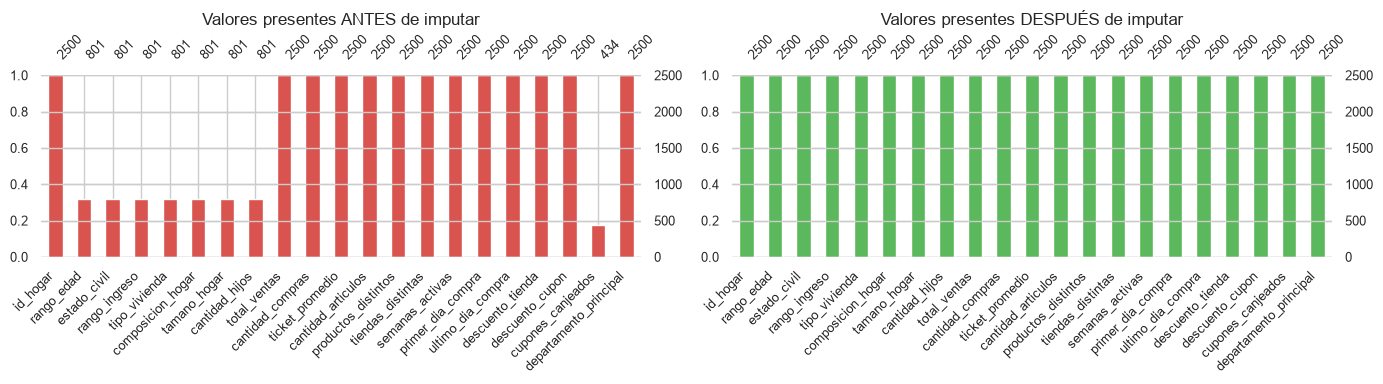

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
msno.bar(df_original.rename(columns=nombres_es), ax=axes[0], fontsize=9, color="#d9534f")
axes[0].set_title("Valores presentes ANTES de imputar")
msno.bar(df.drop(columns="tiene_demografia"), ax=axes[1], fontsize=9, color="#5cb85c")
axes[1].set_title("Valores presentes DESPUÉS de imputar")
plt.tight_layout()
plt.show()

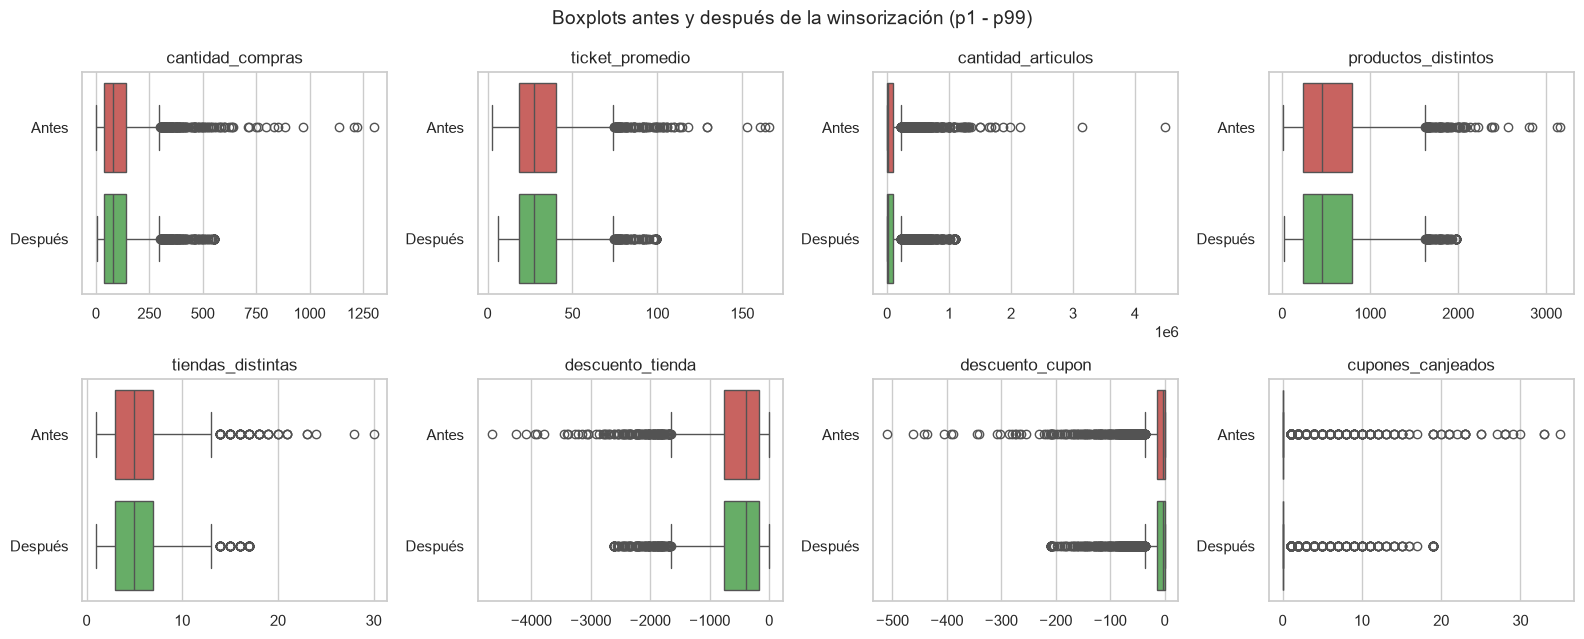

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, col in enumerate(COLS_ACOTAR):
    ax = axes.flat[i]
    comparacion = pd.DataFrame({"Antes": df_antes_atipicos[col], "Después": df[col]}).melt(
        var_name="estado", value_name=col)
    sns.boxplot(data=comparacion, x=col, y="estado", ax=ax, palette=["#d9534f", "#5cb85c"])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Boxplots antes y después de la winsorización (p1 - p99)", fontsize=14)
plt.tight_layout()
plt.show()

In [32]:
pd.DataFrame({
    "max_antes": df_antes_atipicos[COLS_ACOTAR].max(),
    "max_despues": df[COLS_ACOTAR].max(),
    "asimetria_antes": df_antes_atipicos[COLS_ACOTAR].skew(),
    "asimetria_despues": df[COLS_ACOTAR].skew(),
})

,max_antes,max_despues,asimetria_antes,asimetria_despues
cantidad_compras,"1,300.00",553.10,3.37,1.99
ticket_promedio,165.83,99.03,1.72,1.29
cantidad_articulos,"4,479,917.00","1,090,772.69",5.80,3.00
productos_distintos,"3,159.00","1,973.21",1.36,1.13
tiendas_distintas,30.00,17.00,1.46,1.11
descuento_tienda,-0.25,-10.19,-2.12,-1.66
descuento_cupon,0.00,0.00,-5.56,-3.72
cupones_canjeados,35.00,19.00,5.55,4.43


**Resultado:** el dataset quedó **sin nulos** y con las **2 500 filas** originales. La winsorización redujo de forma marcada la asimetría (por ejemplo, el máximo de `cantidad_articulos` bajó de ~4.5 millones a ~1.1 millones, y su asimetría de 5.8 a 3.0) y eliminó los extremos que provenían de errores de unidad, sin descartar ningún hogar.

## 8. Conversión de tipos de datos (punto 9)

| Variable(s) | Tipo original | Tipo final | Motivo |
|---|---|---|---|
| `id_hogar` | `int64` | `string` | Es un **identificador**; no tiene sentido sumarlo ni promediarlo. |
| Variables demográficas y `departamento_principal` | texto | `category` | Tienen pocos valores posibles. `category` usa menos memoria y deja explícito que son variables cualitativas. `rango_edad`, `rango_ingreso`, `tamano_hogar` y `cantidad_hijos` se definen como **categorías ordenadas**. |
| `cupones_canjeados` | `float64` | `int64` | Era `float` solo por los nulos. Ya imputado, es un **conteo entero**. |
| Conteos (`cantidad_compras`, `cantidad_articulos`, `productos_distintos`, `tiendas_distintas`, `semanas_activas`, días) | `int64`/`float64` | `int64` | Son conteos discretos. Después de la winsorización pueden quedar con decimales, así que se redondean. |
| Montos (`total_ventas`, `ticket_promedio`, descuentos) | `float64` | `float64` (2 decimales) | Son montos monetarios continuos. |
| `descuento_tienda`, `descuento_cupon` | negativos | **positivos** | Se convierten a magnitud (monto ahorrado) para que la interpretación sea directa: más alto = más descuento. |

In [33]:
tipos_antes = df.dtypes.astype(str)

ORDEN_EDAD = ["Desconocido", "19-24", "25-34", "35-44", "45-54", "55-64", "65+"]
ORDEN_INGRESO = ["Desconocido", "Under 15K", "15-24K", "25-34K", "35-49K", "50-74K", "75-99K",
                 "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"]
ORDEN_TAMANO = ["Desconocido", "1", "2", "3", "4", "5+"]
ORDEN_HIJOS = ["Desconocido", "None/Unknown", "1", "2", "3+"]

df["id_hogar"] = df["id_hogar"].astype("string")

df["rango_edad"] = pd.Categorical(df["rango_edad"], categories=ORDEN_EDAD, ordered=True)
df["rango_ingreso"] = pd.Categorical(df["rango_ingreso"], categories=ORDEN_INGRESO, ordered=True)
df["tamano_hogar"] = pd.Categorical(df["tamano_hogar"].astype(str), categories=ORDEN_TAMANO, ordered=True)
df["cantidad_hijos"] = pd.Categorical(df["cantidad_hijos"], categories=ORDEN_HIJOS, ordered=True)
for col in ["estado_civil", "tipo_vivienda", "composicion_hogar", "departamento_principal"]:
    df[col] = df[col].astype("category")

COLS_ENTERAS = ["cantidad_compras", "cantidad_articulos", "productos_distintos", "tiendas_distintas",
                "semanas_activas", "primer_dia_compra", "ultimo_dia_compra", "cupones_canjeados"]
df[COLS_ENTERAS] = df[COLS_ENTERAS].round().astype("int64")

df["descuento_tienda"] = df["descuento_tienda"].abs()
df["descuento_cupon"] = df["descuento_cupon"].abs()
COLS_MONTOS = ["total_ventas", "ticket_promedio", "descuento_tienda", "descuento_cupon"]
df[COLS_MONTOS] = df[COLS_MONTOS].astype("float64").round(2)

# Ninguna categoría debe haber quedado sin asignar (NaN) al convertir
assert df.isna().sum().sum() == 0, "Hay valores fuera de las categorías definidas"

pd.DataFrame({"tipo_antes": tipos_antes, "tipo_despues": df.dtypes.astype(str)})

,tipo_antes,tipo_despues
id_hogar,int64,string
rango_edad,str,category
estado_civil,str,category
rango_ingreso,str,category
tipo_vivienda,str,category
composicion_hogar,str,category
tamano_hogar,str,category
cantidad_hijos,str,category
total_ventas,float64,float64
cantidad_compras,float64,int64


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   id_hogar                2500 non-null   string  
 1   rango_edad              2500 non-null   category
 2   estado_civil            2500 non-null   category
 3   rango_ingreso           2500 non-null   category
 4   tipo_vivienda           2500 non-null   category
 5   composicion_hogar       2500 non-null   category
 6   tamano_hogar            2500 non-null   category
 7   cantidad_hijos          2500 non-null   category
 8   total_ventas            2500 non-null   float64 
 9   cantidad_compras        2500 non-null   int64   
 10  ticket_promedio         2500 non-null   float64 
 11  cantidad_articulos      2500 non-null   int64   
 12  productos_distintos     2500 non-null   int64   
 13  tiendas_distintas       2500 non-null   int64   
 14  semanas_activas         2500 non-nu

## 9. Conversión de variables categóricas a numéricas (punto 10)

Se aplican dos técnicas según la naturaleza de cada variable:

**a) Codificación ordinal**, para variables con un **orden natural**: `rango_edad`, `rango_ingreso`, `tamano_hogar` y `cantidad_hijos`. Se asigna un entero que respeta ese orden (por ejemplo, `Under 15K` = 1 … `250K+` = 12). Así se conserva la información de "más o menos" con una sola columna. `Desconocido` se codifica como **0**, y el modelo puede distinguir ese 0 de un valor real gracias al indicador `tiene_demografia`. En `cantidad_hijos`, `None/Unknown` se codifica como 0 hijos: en la mayoría de los casos coincide con composiciones "No Kids".

**b) One-Hot Encoding**, para variables **nominales** sin orden: `estado_civil`, `tipo_vivienda`, `composicion_hogar` y `departamento_principal`. Se crea una columna 0/1 por categoría. Asignarles números consecutivos inventaría un orden inexistente. Se usa `drop_first=True` para evitar la multicolinealidad perfecta (la *trampa de las variables dummy*) en modelos lineales. En `departamento_principal`, las categorías con menos de 1 % de los hogares se agrupan en `OTROS`, para no crear columnas casi vacías.

In [35]:
MAPEO_ORDINAL = {
    "rango_edad":     {c: i for i, c in enumerate(ORDEN_EDAD)},
    "rango_ingreso":  {c: i for i, c in enumerate(ORDEN_INGRESO)},
    "tamano_hogar":   {c: i for i, c in enumerate(ORDEN_TAMANO)},
    "cantidad_hijos": {"Desconocido": 0, "None/Unknown": 0, "1": 1, "2": 2, "3+": 3},
}
for col, mapa in MAPEO_ORDINAL.items():
    print(f"{col}: {mapa}")
    df[col] = df[col].astype(str).map(mapa).astype("int64")

rango_edad: {'Desconocido': 0, '19-24': 1, '25-34': 2, '35-44': 3, '45-54': 4, '55-64': 5, '65+': 6}
rango_ingreso: {'Desconocido': 0, 'Under 15K': 1, '15-24K': 2, '25-34K': 3, '35-49K': 4, '50-74K': 5, '75-99K': 6, '100-124K': 7, '125-149K': 8, '150-174K': 9, '175-199K': 10, '200-249K': 11, '250K+': 12}
tamano_hogar: {'Desconocido': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5+': 5}
cantidad_hijos: {'Desconocido': 0, 'None/Unknown': 0, '1': 1, '2': 2, '3+': 3}


In [36]:
# Agrupar departamentos poco frecuentes (< 1 % de los hogares)
frecuencia = df["departamento_principal"].value_counts(normalize=True)
poco_frecuentes = frecuencia[frecuencia < 0.01].index
df["departamento_principal"] = (df["departamento_principal"].astype(str)
                                .replace(list(poco_frecuentes), "OTROS"))
print("Departamentos agrupados en OTROS:", list(poco_frecuentes))
print(df["departamento_principal"].value_counts().to_string())

Departamentos agrupados en OTROS: ['MEAT', 'MISC SALES TRAN', 'PRODUCE', 'NUTRITION', 'PASTRY', 'DELI', 'SPIRITS', 'COSMETICS', 'MEAT-PCKGD', 'SALAD BAR']
departamento_principal
GROCERY      2380
DRUG GM        63
OTROS          31
KIOSK-GAS      26


In [37]:
COLS_NOMINALES = ["estado_civil", "tipo_vivienda", "composicion_hogar", "departamento_principal"]
df = pd.get_dummies(df, columns=COLS_NOMINALES, drop_first=True, dtype="int64")

print(f"Dimensiones tras la codificación: {df.shape}")
print("\nTipos de datos resultantes:")
print(df.dtypes.value_counts().to_string())
df.head()

Dimensiones tras la codificación: (2500, 32)

Tipos de datos resultantes:
int64      27
float64     4
string      1


,id_hogar,rango_edad,rango_ingreso,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,cantidad_articulos,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,tiene_demografia,estado_civil_Desconocido,estado_civil_Soltero,tipo_vivienda_Homeowner,tipo_vivienda_Probable Owner,tipo_vivienda_Probable Renter,tipo_vivienda_Renter,composicion_hogar_2 Adults Kids,composicion_hogar_2 Adults No Kids,composicion_hogar_Desconocido,composicion_hogar_Single Female,composicion_hogar_Single Male,departamento_principal_GROCERY,departamento_principal_KIOSK-GAS,departamento_principal_OTROS
0,1,6,4,2,0,"4,330.16",86,50.35,1997,677,2,68,51,706,697.04,80.56,5,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0
1,2,0,0,0,0,"1,954.34",45,43.43,834,546,5,35,103,668,334.99,9.00,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
2,3,0,0,0,0,"2,653.21",47,56.45,8540,516,3,37,113,703,675.16,61.19,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
3,4,0,0,0,0,"1,200.11",30,40.00,382,164,6,26,104,627,115.65,2.50,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
4,5,0,0,0,0,779.06,40,19.48,245,199,3,27,85,703,118.33,0.00,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0


## 10. Estandarización (punto 11)

Se elige la **estandarización Z-score** (`StandardScaler`, $z = \frac{x - \mu}{\sigma}$) en lugar de la normalización Min-Max, por tres razones:

* Las variables tienen **escalas muy distintas** (`cantidad_articulos` llega a millones, mientras que `tiendas_distintas` no pasa de 20). Sin escalar, las de mayor magnitud dominarían en los modelos basados en distancias o en gradiente.
* Min-Max es **muy sensible a los extremos**: aunque ya se acotaron, las distribuciones siguen siendo asimétricas y Min-Max comprimiría a la mayoría de los hogares cerca de 0.
* Z-score centra en 0 con desviación 1, que es lo que esperan la regresión lineal regularizada, KNN, SVM y PCA.

**Qué se escala y qué no:**
* ✅ Las métricas numéricas continuas y los códigos ordinales.
* ❌ `id_hogar` (identificador).
* ❌ `total_ventas`: es la **variable objetivo** y se deja en su escala original (dólares) para que las predicciones se puedan interpretar.
* ❌ Las variables binarias 0/1 (one-hot y `tiene_demografia`): ya están en una escala comparable y conservan su interpretación.

In [38]:
COLS_ORDINALES = list(MAPEO_ORDINAL.keys())
COLS_ESCALAR = COLS_ORDINALES + [c for c in COLS_NUMERICAS if c != "total_ventas"]

df_sin_escalar = df.copy()
escalador = StandardScaler()
df[COLS_ESCALAR] = escalador.fit_transform(df[COLS_ESCALAR])

pd.DataFrame({
    "media_antes": df_sin_escalar[COLS_ESCALAR].mean(),
    "desv_antes": df_sin_escalar[COLS_ESCALAR].std(),
    "media_despues": df[COLS_ESCALAR].mean().round(4),
    "desv_despues": df[COLS_ESCALAR].std().round(4),
})

,media_antes,desv_antes,media_despues,desv_despues
rango_edad,1.12,1.78,-0.00,1.00
rango_ingreso,1.51,2.54,-0.00,1.00
tamano_hogar,0.70,1.23,0.00,1.00
cantidad_hijos,0.18,0.60,0.00,1.00
cantidad_compras,108.40,102.09,0.00,1.00
ticket_promedio,31.46,18.19,0.00,1.00
cantidad_articulos,"98,786.05","201,790.23",0.00,1.00
productos_distintos,557.67,423.60,0.00,1.00
tiendas_distintas,5.43,3.38,-0.00,1.00
semanas_activas,49.59,25.54,-0.00,1.00


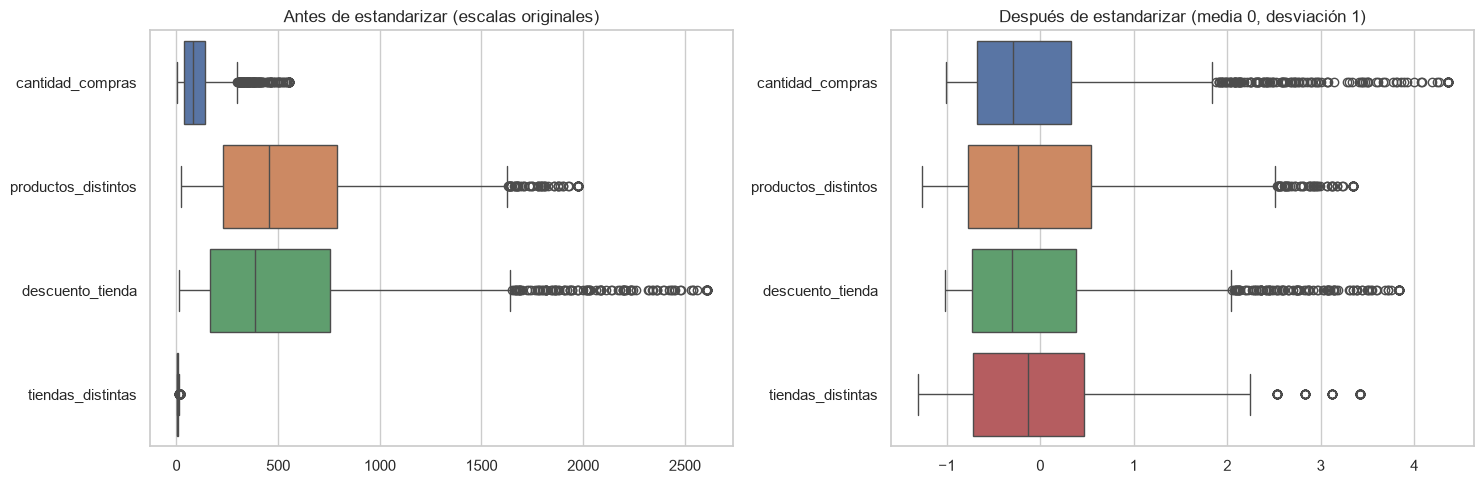

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ejemplo = ["cantidad_compras", "productos_distintos", "descuento_tienda", "tiendas_distintas"]
sns.boxplot(data=df_sin_escalar[ejemplo], orient="h", ax=axes[0])
axes[0].set_title("Antes de estandarizar (escalas originales)")
sns.boxplot(data=df[ejemplo], orient="h", ax=axes[1])
axes[1].set_title("Después de estandarizar (media 0, desviación 1)")
plt.tight_layout()
plt.show()

## 11. Correlación de las variables (punto 12)

Se calcula la **correlación de Pearson** entre las variables numéricas, ordinales y el indicador. La estandarización no altera la correlación de Pearson, que es invariante a cambios lineales de escala. Las variables one-hot se analizan aparte con respecto a la variable objetivo.

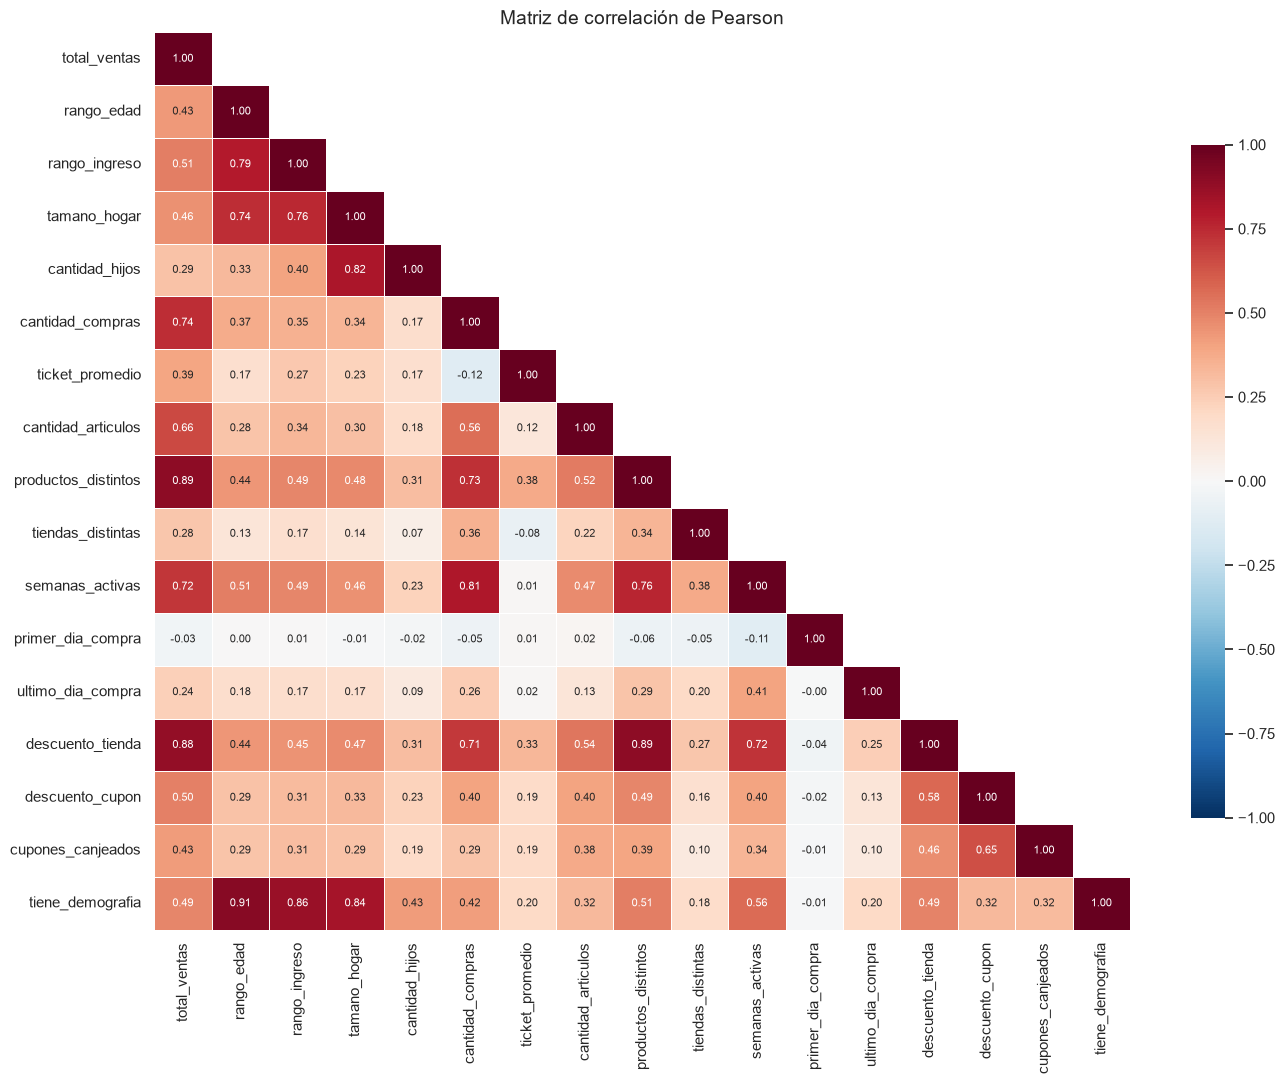

In [40]:
COLS_CORR = ["total_ventas"] + COLS_ESCALAR + ["tiene_demografia"]
matriz_corr = df[COLS_CORR].corr(method="pearson")

mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.75}, ax=ax,
            annot_kws={"size": 8})
ax.grid(False)
ax.set_title("Matriz de correlación de Pearson", fontsize=14)
plt.tight_layout()
plt.show()

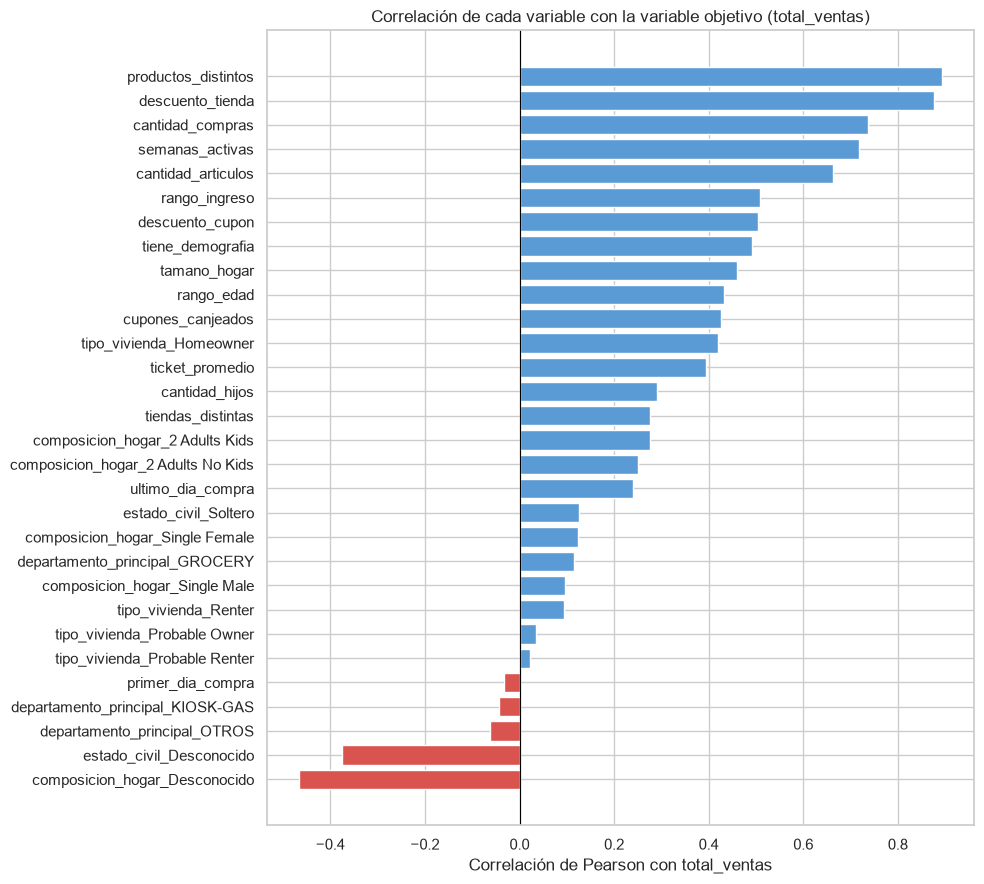

In [41]:
corr_objetivo = df.drop(columns="id_hogar").corr()["total_ventas"].drop("total_ventas").sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
colores = ["#d9534f" if v < 0 else "#5b9bd5" for v in corr_objetivo]
ax.barh(corr_objetivo.index, corr_objetivo.values, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación de Pearson con total_ventas")
ax.set_title("Correlación de cada variable con la variable objetivo (total_ventas)")
plt.tight_layout()
plt.show()

In [42]:
# Pares de variables explicativas con correlación fuerte (|r| >= 0.7): riesgo de multicolinealidad
pares = (matriz_corr.where(~np.tril(np.ones_like(matriz_corr, dtype=bool)))
         .stack().rename("r").reset_index())
pares.columns = ["variable_1", "variable_2", "r"]
pares[pares["r"].abs() >= 0.7].sort_values("r", key=abs, ascending=False)

,variable_1,variable_2,r
33,rango_edad,tiene_demografia,0.91
149,productos_distintos,descuento_tienda,0.89
8,total_ventas,productos_distintos,0.89
13,total_ventas,descuento_tienda,0.88
50,rango_ingreso,tiene_demografia,0.86
67,tamano_hogar,tiene_demografia,0.84
55,tamano_hogar,cantidad_hijos,0.82
95,cantidad_compras,semanas_activas,0.81
19,rango_edad,rango_ingreso,0.79
146,productos_distintos,semanas_activas,0.76


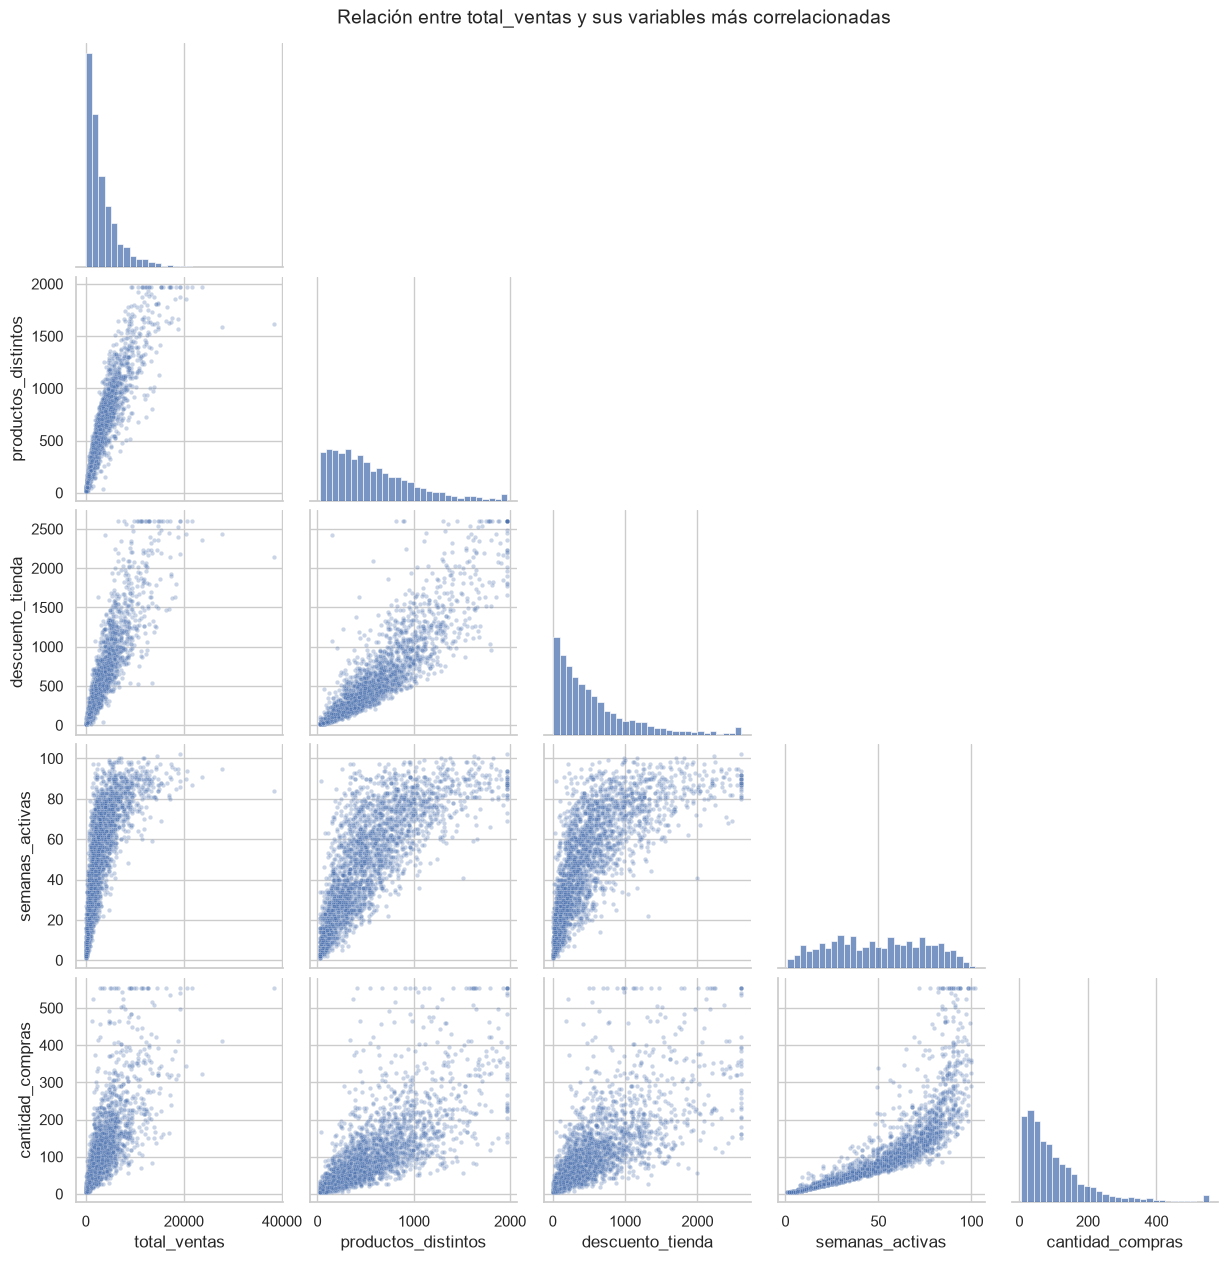

In [43]:
sns.pairplot(df_sin_escalar[["total_ventas", "productos_distintos", "descuento_tienda",
                             "semanas_activas", "cantidad_compras"]],
             corner=True, plot_kws={"alpha": 0.3, "s": 10}, diag_kws={"bins": 30})
plt.suptitle("Relación entre total_ventas y sus variables más correlacionadas", y=1.01, fontsize=14)
plt.show()

**Hallazgos de correlación**

* **`total_ventas`** tiene una correlación **muy fuerte** con `productos_distintos` (≈ 0.90) y `descuento_tienda` (≈ 0.87; positiva porque el descuento ya se pasó a magnitud). Tiene una correlación **fuerte** con `cantidad_compras` (0.74), `semanas_activas` (0.72) y `cantidad_articulos` (0.66). Los hogares que gastan más son los que compran **más seguido, más variedad y durante más semanas**.
* **`ticket_promedio`** se relaciona de forma moderada con las ventas, pero casi nada con `cantidad_compras`: hay dos perfiles distintos, el de "muchas compras pequeñas" y el de "pocas compras grandes".
* Hay **multicolinealidad** entre las variables explicativas: `productos_distintos`, `descuento_tienda`, `semanas_activas` y `cantidad_compras` están correlacionadas entre sí (|r| > 0.7). Esto debe considerarse si se usa regresión lineal (regularización, o seleccionar una de cada grupo).
* **`tiene_demografia`** tiene una correlación de 0.49 con las ventas: **los hogares que respondieron la encuesta demográfica gastan más**. Esto confirma que crear el indicador en la imputación fue útil.
* Las variables ordinales (`rango_edad`, `rango_ingreso`, `tamano_hogar`) aparecen con r ≈ 0.43-0.51 y **muy correlacionadas con `tiene_demografia` (0.84-0.91)**. Es un **efecto de la codificación**: todos los "Desconocido" valen 0 y coinciden con los hogares de menor gasto. Para medir su efecto real se repite la correlación **solo en los 801 hogares con demografía** (celda siguiente). El ingreso queda con una relación positiva débil y la edad prácticamente no influye.
* `primer_dia_compra` no tiene relación con las ventas (r ≈ −0.03).

In [44]:
con_demografia = df_sin_escalar[df_sin_escalar["tiene_demografia"] == 1]
(con_demografia[["rango_ingreso", "tamano_hogar", "cantidad_hijos", "rango_edad", "total_ventas"]]
 .corr()["total_ventas"].drop("total_ventas").sort_values(ascending=False)
 .to_frame("r con total_ventas (solo 801 hogares con demografía)"))

,r con total_ventas (solo 801 hogares con demografía)
rango_ingreso,0.26
tamano_hogar,0.14
cantidad_hijos,0.14
rango_edad,-0.06


## 12. Variable dependiente y modelo candidato (punto 13)

### Variable dependiente: `total_ventas`

El objetivo de negocio de un data warehouse de ventas es entender y **predecir cuánto gasta un hogar** para segmentar clientes, dirigir campañas y estimar ingresos. Por eso se define como variable dependiente **`total_ventas`** (gasto total del hogar en dólares). Es una variable **numérica continua**, así que el problema es de **REGRESIÓN**.

**Precaución contra fuga de información (*data leakage*):** `ticket_promedio` se calculó como `total_ventas / cantidad_compras`, y los descuentos son proporcionales al monto comprado. Si se usan como predictores, el modelo "haría trampa". Por eso se **excluyen** para validar el modelo.

### Modelos candidatos (de los estudiados en el curso)

1. **Regresión Lineal Múltiple**: modelo interpretable (cada coeficiente indica cuánto cambian las ventas por unidad de la variable). La relación lineal fuerte que muestra la matriz de correlación la hace un buen candidato. Es sensible a la multicolinealidad detectada, así que conviene acompañarla con regularización (**Ridge**).
2. **Random Forest Regressor**: capta relaciones **no lineales** y las interacciones entre variables (por ejemplo, frecuencia × variedad). Es **robusto** frente a atípicos y multicolinealidad.

Se hace una validación cruzada rápida (5 particiones) para respaldar la elección con evidencia:

In [45]:
COLS_FUGA = ["id_hogar", "total_ventas", "ticket_promedio", "descuento_tienda", "descuento_cupon"]
X = df.drop(columns=COLS_FUGA)
y = df["total_ventas"]
print(f"Predictores: {X.shape[1]} | Observaciones: {X.shape[0]}")

modelos = {
    "Regresión Lineal Múltiple": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
for nombre, modelo in modelos.items():
    cv = cross_validate(modelo, X, y, cv=kfold,
                        scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    resultados.append({"modelo": nombre,
                       "R2": cv["test_r2"].mean(),
                       "MAE ($)": -cv["test_neg_mean_absolute_error"].mean(),
                       "RMSE ($)": -cv["test_neg_root_mean_squared_error"].mean()})
pd.DataFrame(resultados).set_index("modelo").style.format({"R2": "{:.3f}", "MAE ($)": "{:,.1f}", "RMSE ($)": "{:,.1f}"})

Predictores: 27 | Observaciones: 2500


,R2,MAE ($),RMSE ($)
modelo,,,
Regresión Lineal Múltiple,0.863,706.6,"1,235.4"
Random Forest Regressor,0.855,652.5,"1,270.0"


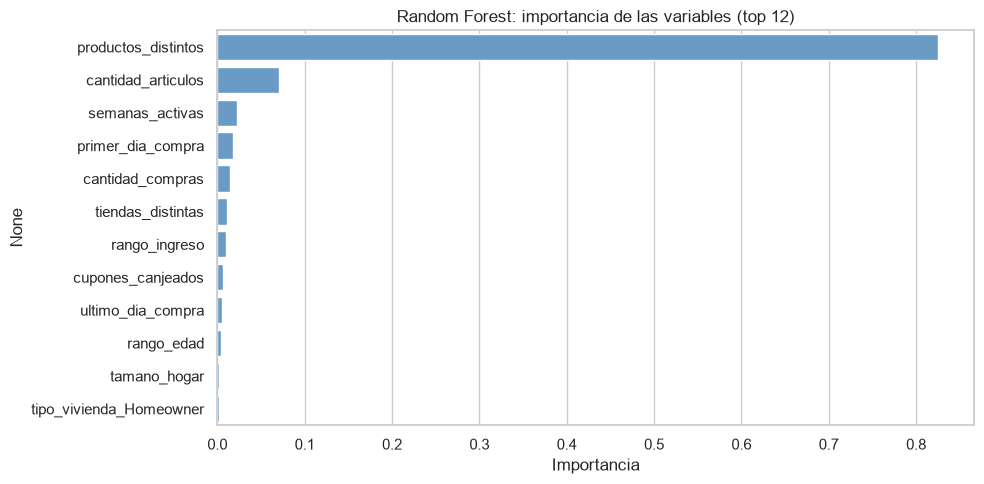

In [46]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X, y)
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=importancia.values, y=importancia.index, color="#5b9bd5", ax=ax)
ax.set_title("Random Forest: importancia de las variables (top 12)")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.show()

**Conclusión:** el problema es de **regresión**, con `total_ventas` como variable dependiente. Los dos modelos explican cerca del **86 % de la varianza** de las ventas sin usar las variables con fuga de información.

* La **Regresión Lineal Múltiple** obtiene un R² ligeramente mayor (≈ 0.863 frente a ≈ 0.855) y un RMSE menor, es decir, se equivoca menos en los hogares de gasto alto.
* El **Random Forest** obtiene un MAE menor, es decir, se equivoca menos en el hogar típico.

✅ **Modelo recomendado: Regresión Lineal Múltiple (con regularización Ridge).** Rinde igual o mejor, es más simple y es **interpretable**: el negocio puede saber cuánto aporta cada semana activa o cada producto distinto al gasto. La regularización Ridge controla la multicolinealidad detectada en la sección 11. **Random Forest Regressor** queda como alternativa si en el futuro se agregan variables con relaciones no lineales; además, su importancia de variables confirma qué factores explican el gasto.

*Alternativa de clasificación:* si el negocio prefiere **segmentar** (por ejemplo, hogares de valor "alto" frente a "bajo" según la mediana de `total_ventas`), el mismo dataset sirve para un problema de **clasificación** con Árbol de Decisión, Random Forest Classifier o Regresión Logística.

## 13. Guardado del conjunto de datos procesado (punto 14)

Se guarda el dataset con **todas las transformaciones del EDA aplicadas** (columnas en español, nulos imputados, atípicos acotados, tipos convertidos, categóricas codificadas y variables estandarizadas) en el archivo **`data_process.csv`**.

In [47]:
df.to_csv("data_process.csv", index=False, encoding="utf-8")

verificacion = pd.read_csv("data_process.csv")
print(f"Archivo guardado: data_process.csv -> {verificacion.shape[0]:,} filas x {verificacion.shape[1]} columnas")
print(f"Nulos en el archivo guardado: {verificacion.isna().sum().sum()}")
verificacion.head()

Archivo guardado: data_process.csv -> 2,500 filas x 32 columnas
Nulos en el archivo guardado: 0


,id_hogar,rango_edad,rango_ingreso,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,cantidad_articulos,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,tiene_demografia,estado_civil_Desconocido,estado_civil_Soltero,tipo_vivienda_Homeowner,tipo_vivienda_Probable Owner,tipo_vivienda_Probable Renter,tipo_vivienda_Renter,composicion_hogar_2 Adults Kids,composicion_hogar_2 Adults No Kids,composicion_hogar_Desconocido,composicion_hogar_Single Female,composicion_hogar_Single Male,departamento_principal_GROCERY,departamento_principal_KIOSK-GAS,departamento_principal_OTROS
0,1,2.74,0.98,1.06,-0.29,"4,330.16",-0.22,1.04,-0.48,0.28,-1.02,0.72,-0.38,0.33,0.27,1.91,1.48,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0
1,2,-0.63,-0.59,-0.57,-0.29,"1,954.34",-0.62,0.66,-0.49,-0.03,-0.13,-0.57,0.95,-0.28,-0.41,-0.21,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
2,3,-0.63,-0.59,-0.57,-0.29,"2,653.21",-0.60,1.37,-0.45,-0.10,-0.72,-0.49,1.20,0.28,0.23,1.34,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
3,4,-0.63,-0.59,-0.57,-0.29,"1,200.11",-0.77,0.47,-0.49,-0.93,0.17,-0.92,0.97,-0.93,-0.82,-0.40,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
4,5,-0.63,-0.59,-0.57,-0.29,779.06,-0.67,-0.66,-0.49,-0.85,-0.72,-0.88,0.49,0.28,-0.81,-0.47,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0


---

## Resumen del proceso EDA

| Paso | Resultado |
|---|---|
| Carga | 2 500 hogares × 21 variables, leídos desde GitHub |
| Renombrado | 21 columnas traducidas al español |
| Nulos | 7 demográficas (68 %, en bloque) + `cupones_canjeados` (83 %, nulo estructural) |
| Imputación | `"Desconocido"` + indicador `tiene_demografia`; cupones → 0 |
| Atípicos | Detectados con IQR. Se winsorizaron en p1-p99 8 métricas, sin eliminar filas |
| Tipos | Identificador → texto, categóricas → `category`, conteos → `int`, descuentos → positivos |
| Codificación | Ordinal (edad, ingreso, tamaño, hijos) y One-Hot (estado civil, vivienda, composición, departamento) |
| Escalado | `StandardScaler` (Z-score) sobre 15 variables; el objetivo se conserva en dólares |
| Correlación | Ventas ↔ variedad de productos, frecuencia y semanas activas; multicolinealidad entre ellas |
| Modelo | **Regresión** sobre `total_ventas`; recomendado **Regresión Lineal Múltiple (Ridge)**, R² ≈ 0.86 |
| Salida | `data_process.csv` |